In [1]:
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:

import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

print("Qiskit setup successful!")

Qiskit setup successful!


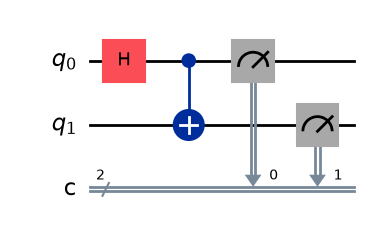

In [3]:

# Create a circuit with exactly 2 qubits and 2 classical bits
qc_original = QuantumCircuit(2, 2)

# Step 1: Put qubit 0 into superposition
qc_original.h(0)

# Step 2: Entangle the two qubits using CNOT
qc_original.cx(0, 1)

# Step 3: Measure both qubits
qc_original.measure([0, 1], [0, 1])

# Display the circuit
qc_original.draw("mpl")

### Prediction — Original Bell-state circuit

I expect the measurement outcomes 00 and 11 to occur approximately 50% of the time each. The outcomes 01 and 10 should not occur in an ideal simulator because the two qubits are correlated.

For 100 shots, I expect approximately 50 counts of 00 and 50 counts of 11, although the actual counts may vary due to random sampling.


In [4]:

simulator = AerSimulator()

compiled_original = transpile(qc_original, simulator)

job_original = simulator.run(compiled_original, shots=100)
result_original = job_original.result()

counts_original = result_original.get_counts()

print("Original circuit results:", counts_original)
print("Total shots:", sum(counts_original.values()))

Original circuit results: {'11': 52, '00': 48}
Total shots: 100


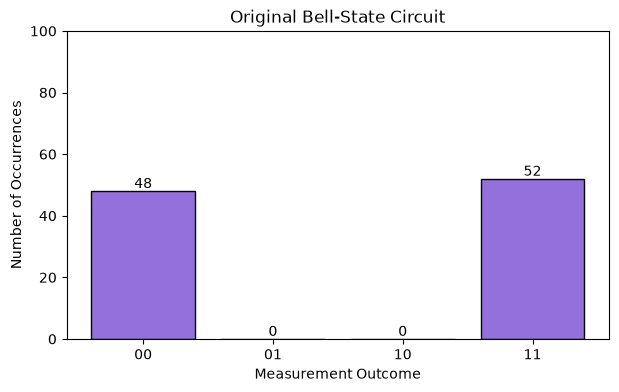

In [5]:

outcomes = ["00", "01", "10", "11"]

original_values = [
    counts_original.get(outcome, 0)
    for outcome in outcomes
]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    outcomes,
    original_values,
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Original Bell-State Circuit")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Occurrences")
plt.ylim(0, 100)

for bar, value in zip(bars, original_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        str(value),
        ha="center"
    )

plt.show()

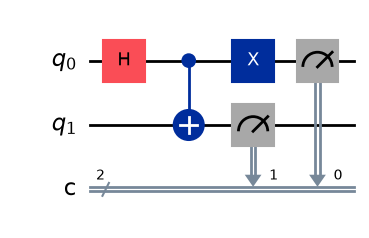

In [6]:

# Create the modified circuit with exactly 2 qubits and 2 classical bits
qc_modified = QuantumCircuit(2, 2)

# Keep the original Bell-state gates
qc_modified.h(0)
qc_modified.cx(0, 1)

# Add ONE new quantum gate to change the correlation pattern
qc_modified.x(0)

# Measure both qubits
qc_modified.measure([0, 1], [0, 1])

# Display the modified circuit
qc_modified.draw("mpl")

### Prediction — Modified Bell-state circuit

I added an X gate to qubit 0 after the CNOT gate. This flips the measurement value of that qubit.

I predict that outcomes 01 and 10 will occur approximately 50% of the time each, while outcomes 00 and 11 will not occur in an ideal simulator.

For 100 shots, I expect approximately 50 counts of 01 and 50 counts of 10. This modification changes the relationship between the two measurement outcomes from matching bits to opposite bits.


In [7]:

compiled_modified = transpile(qc_modified, simulator)

job_modified = simulator.run(compiled_modified, shots=100)
result_modified = job_modified.result()

counts_modified = result_modified.get_counts()

print("Modified circuit results:", counts_modified)
print("Total shots:", sum(counts_modified.values()))

Modified circuit results: {'01': 54, '10': 46}
Total shots: 100


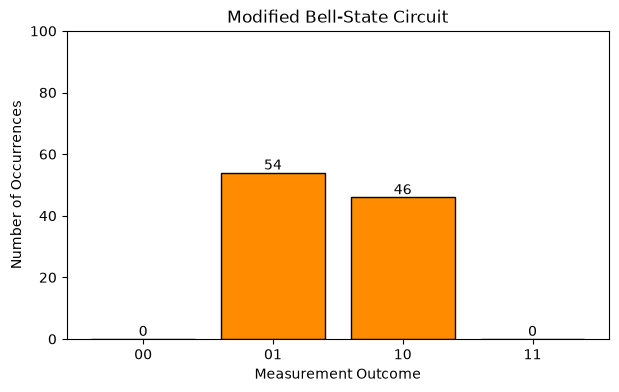

In [8]:

modified_values = [
    counts_modified.get(outcome, 0)
    for outcome in outcomes
]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    outcomes,
    modified_values,
    color="darkorange",
    edgecolor="black"
)

plt.title("Modified Bell-State Circuit")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Occurrences")
plt.ylim(0, 100)

for bar, value in zip(bars, modified_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        str(value),
        ha="center"
    )

plt.show()

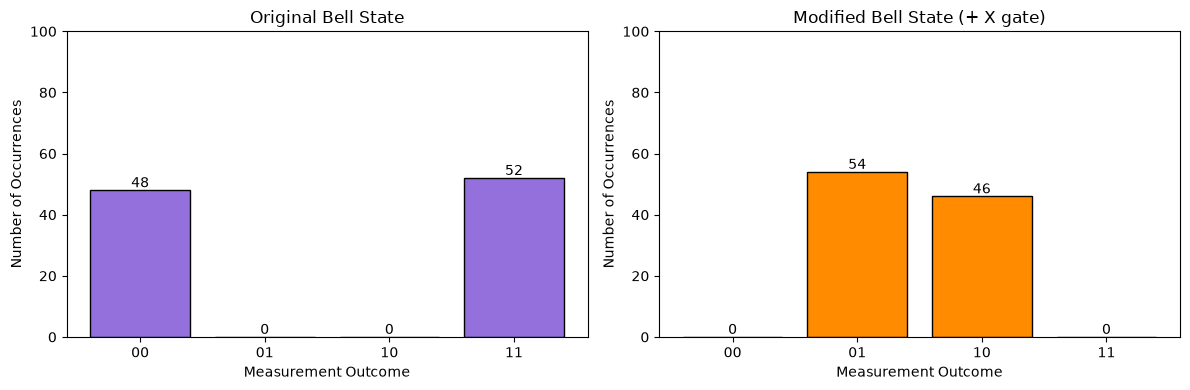

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

datasets = [
    (counts_original, "Original Bell State"),
    (counts_modified, "Modified Bell State (+ X gate)")
]

for ax, (counts, title) in zip(axes, datasets):
    values = [counts.get(outcome, 0) for outcome in outcomes]

    bars = ax.bar(
        outcomes,
        values,
        color="mediumpurple" if "Original" in title else "darkorange",
        edgecolor="black"
    )

    ax.set_title(title)
    ax.set_xlabel("Measurement Outcome")
    ax.set_ylabel("Number of Occurrences")
    ax.set_ylim(0, 100)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1,
            str(value),
            ha="center"
        )

plt.tight_layout()
plt.show()

### Challenge 3: Can You Change the Correlation?

The original circuit uses a Hadamard gate followed by a CNOT gate to create a Bell state. When measured over 100 shots, the outcomes 00 and 11 are expected to occur approximately equally often. These outcomes show that the two qubits produce matching measurement results.

In the modified circuit, I added an X gate to qubit 0 after the CNOT gate. The X gate flips the measurement value of that qubit, changing the expected outcomes from 00 and 11 to 01 and 10.

After executing both circuits for 100 shots, I compared their measurement counts and histograms. The original circuit produces matching bits, while the modified circuit produces opposite bits.

Therefore, adding a single X gate changes the correlation pattern between the two qubits. The results demonstrate how quantum gates can modify measurement relationships in an entangled quantum system.
